# Exploratory Data Analysis (EDA)
In this notebook, we explore the set of **premise–hypothesis** pairs and their class labels. The goal is to understand the data before preparing text for a model and to justify preprocessing decisions based on our observations.

## 1. Load the data

We load the training data in  `data/train.csv` y and show them

In [60]:
from pathlib import Path
import pandas as pd

columns = ["id", "premise", "hypothesis", "lang_abv", "language", "label"]
train_path = Path("data/train.csv")

df_train = pd.read_csv(train_path)

df_train["label"] = pd.to_numeric(df_train["label"]).astype(int)

result_dict = {0: "entailment", 1: "neutral", 2: "contradiction"}
print(f"File: {train_path}")
print(f"Rows: {len(df_train)} | Columns: {len(df_train.columns)}")

df_train.head()


File: data/train.csv
Rows: 12120 | Columns: 6


,id,premise,hypothesis,lang_abv,language,label
0,5130fd2cb5,and these comments were considered in formulat...,The rules developed in the interim were put to...,en,English,0
1,5b72532a0b,These are issues that we wrestle with in pract...,Practice groups are not permitted to work on t...,en,English,2
2,3931fbe82a,Des petites choses comme celles-là font une di...,J'essayais d'accomplir quelque chose.,fr,French,0
3,5622f0c60b,you know they can't really defend themselves l...,They can't defend themselves because of their ...,en,English,0
4,86aaa48b45,ในการเล่นบทบาทสมมุติก็เช่นกัน โอกาสที่จะได้แสด...,เด็กสามารถเห็นได้ว่าชาติพันธุ์แตกต่างกันอย่างไร,th,Thai,1


## 2. Check the structure of the dataset and missing values

We check data types, null values, and empty fields or fields consisting only of spaces.

In [61]:
print("Data types:")
display(df_train.dtypes.to_frame())

missing_values = pd.DataFrame({
    "missing": df_train.isnull().sum(),
    "empty": df_train.apply(
        lambda columna: columna.astype(str).str.strip().eq("").sum()
    ),
})
print("Missing values per column:")
display(missing_values)

Data types:


,0
id,str
premise,str
hypothesis,str
lang_abv,str
language,str
label,int64


Missing values per column:


,missing,empty
id,0,0
premise,0,0
hypothesis,0,0
lang_abv,0,0
language,0,0
label,0,0


## 3. Class Frequency and Languages

The labels mean: **0 = entailment**, **1 = neutral**, and **2 = contradiction**. First, we observe the balance between classes; then, how many examples there are per language.

,class,rows,percentage
label,,,
0,entailment,4176,34.5
1,neutral,3880,32.0
2,contradiction,4064,33.5


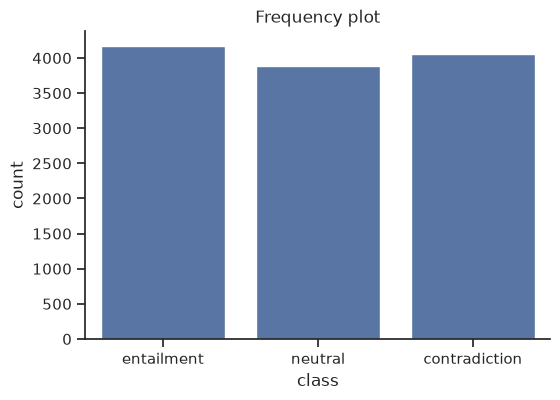

,lang_abv,language,rows,frequency
4,en,English,6870,56.7
14,zh,Chinese,411,3.4
0,ar,Arabic,401,3.3
6,fr,French,390,3.2
9,sw,Swahili,385,3.2
12,ur,Urdu,381,3.1
13,vi,Vietnamese,379,3.1
8,ru,Russian,376,3.1
7,hi,Hindi,374,3.1
3,el,Greek,372,3.1


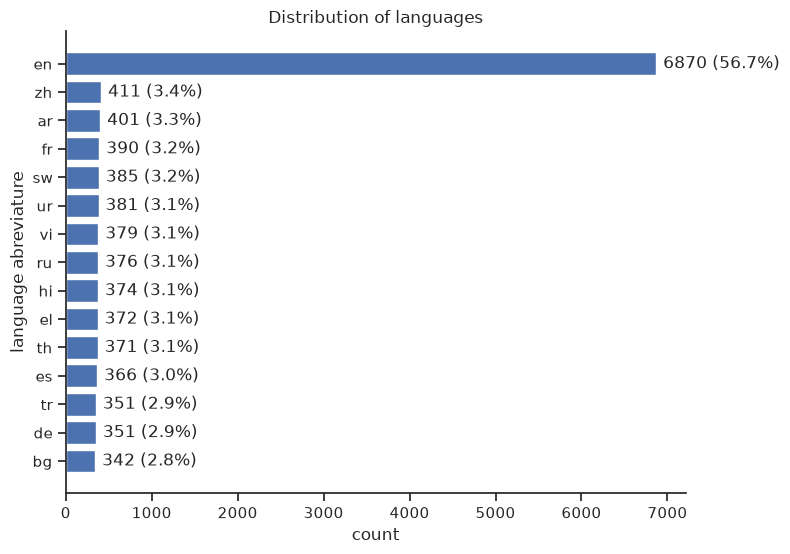

In [62]:
import matplotlib.pyplot as plt
import seaborn as sns

# freq per class/label
class_freq = (df_train["label"].value_counts().sort_index().rename_axis("label").to_frame("rows"))
class_freq["class"] = class_freq.index.map(result_dict)
class_freq["percentage"] = (class_freq["rows"] / len(df_train) * 100).round(1)
display(class_freq[["class", "rows", "percentage"]])

sns.set_theme(style="ticks")
fig, ax = plt.subplots(figsize=(6, 4))
ax = sns.barplot( data=class_freq, x="class", y="rows", ax=ax)
ax.set_title("Frequency plot")
ax.set_xlabel("class")
ax.set_ylabel("count")
sns.despine()
plt.show()

# Dataframe freq per lang
class_freq = (df_train.groupby(["lang_abv", "language"]).size().reset_index(name="rows").sort_values("rows", ascending=False))
class_freq["frequency"] = (class_freq["rows"] / len(df_train) * 100).round(1)
display(class_freq)

# figure freq per lang
fig, ax = plt.subplots(figsize=(8, 6))
df_plot = class_freq.sort_values("rows", ascending=True)
bars = ax.barh(df_plot["lang_abv"], df_plot["rows"])

# Create labels with count and percentage
lbls = [f'{row} ({pct:.1f}%)' for row, pct in zip(df_plot["rows"], df_plot["frequency"])]
ax.bar_label(bars, labels=lbls, padding=5)

ax.set_title("Distribution of languages")
ax.set_xlabel("count")
ax.set_ylabel("language abreviature")
sns.despine()
plt.show()

From this, we can conclude that the data is well balanced, providing a similar number of rows where the result is 'entailment', 'neutral', and 'contradiction'. This is a significant advantage, as we won't need to perform oversampling or undersampling to balance the dataset.

On the other hand, we see a majority of samples in English, being this a 56% of the total. The other languages ​​are relatively lower, but there are still a significant number.

## 4. Duplicates and Repeated Premises

We distinguish between completely repeated rows or pairs and **premises shared by several hypotheses**. A repeated premise does not have to be a duplicate as it can form several valid examples with different labels.

In [63]:
multiple_labels_pairs = (df_train.groupby(["premise", "hypothesis"])["label"].nunique().gt(1).sum())
duplicates_summary = pd.DataFrame({
    "check": [
        "Duplicate rows",
        "Repeated (premise, hypothesis) pairs",
        "Identical pairs with more than one label",
        "Unique premises",
        "Premises appearing more than once",
        "Rows belonging to a repeated premise",
        "Hypotheses appearing more than once",
        "Rows where premise and hypothesis are equal",
    ],
    "count": [
        int(df_train.duplicated().sum()),
        int(df_train.duplicated(["premise", "hypothesis"]).sum()),
        int(multiple_labels_pairs),
        int(df_train["premise"].nunique()),
        int(df_train["premise"].value_counts().gt(1).sum()),
        int(df_train["premise"].value_counts().loc[lambda s: s > 1].sum()),
        int(df_train["hypothesis"].value_counts().gt(1).sum()),
        int(df_train["premise"].eq(df_train["hypothesis"]).sum()),
    ],
})
display(duplicates_summary)

counts_per_premise = df_train["premise"].value_counts()
repeated_premise_sizes = counts_per_premise[counts_per_premise > 1]
sizes_summary = (repeated_premise_sizes.value_counts().sort_index().
                 rename_axis("rows_with_same_premise").to_frame("number_of_premises")
                 )
sizes_summary["affected_rows"] = (
    sizes_summary.index * sizes_summary["number_of_premises"]
)
print("Size of shared premise groups:")
display(sizes_summary)

labels_per_premise = df_train.groupby("premise")["label"].nunique()
print("Repeated premises associated with more than one label:",
    int((labels_per_premise.loc[repeated_premise_sizes.index] > 1).sum()),
)

,check,count
0,Duplicate rows,0
1,"Repeated (premise, hypothesis) pairs",0
2,Identical pairs with more than one label,0
3,Unique premises,8209
4,Premises appearing more than once,2800
5,Rows belonging to a repeated premise,6711
6,Hypotheses appearing more than once,1
7,Rows where premise and hypothesis are equal,1


Size of shared premise groups:


,number_of_premises,affected_rows
rows_with_same_premise,,
2,1689,3378
3,1111,3333


Repeated premises associated with more than one label: 2669


From this, we can deduce that, first of all, there are no rows with the same data in all their columns, nor the same premise and hypothesis. In other words, there is no duplicate data. Furthermore, of the 12,120 premises in the dataset, 8,209 are distinct. Some premises are used in more than one row of the dataset, but these are associated with different hypotheses. Of these, 1,689 appear twice in the dataset, while 1,111 appear three times. Of these repeated premises, 2,669 are associated with more than one label, normal since they are associated with different hypotheses.

Finally, there is only one duplicate hypothesis in a single row and one row where the premise and hypothesis are identical (the same text).

With this, we can see that although there are duplicate premises, these are not simply redundant duplicates, but rather cases where the same premise is tested against different hypotheses. This can affect us during the train/test split and cause a data leak if the same premise appears in both the training and test sets.

## 5. Text lengths 
We measure characters and space-separated units based on premises and hypotheses. The second measure is only approximate: in languages ​​like Chinese, words are not necessarily separated by spaces. Therefore, we should not treat space-separated counts as a comparable measure of words for all languages.

Statistical summary of the number of characters:


,premise_length,hypothesis_length
count,12120.0,12120.0
mean,107.4,53.9
std,71.1,25.3
min,4.0,4.0
25%,55.0,36.0
50%,96.0,51.0
75%,146.0,67.0
max,967.0,276.0


Median summary per language:


,p_chars,p_spaced,h_chars,h_spaced,rows
lang_abv,,,,,
en,95.0,16.0,53.0,9.0,6870
zh,32.0,1.0,15.0,1.0,411
ar,83.0,15.0,40.0,7.0,401
fr,113.5,19.0,57.0,10.0,390
sw,96.0,15.0,49.0,7.0,385
ur,99.0,21.0,47.0,10.0,381
vi,109.0,24.0,52.0,12.0,379
ru,104.5,16.0,50.0,8.0,376
hi,100.0,20.0,51.5,10.0,374


Length distribution in premises and hypothesis:


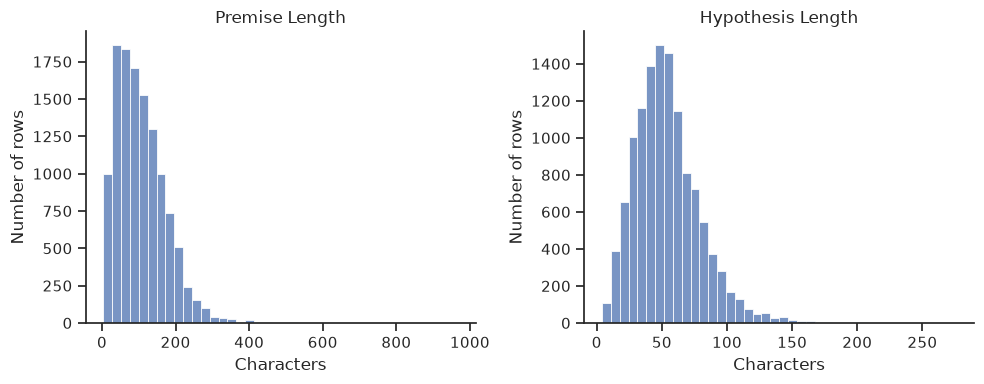

In [68]:
df_train["premise_length"] = df_train["premise"].apply(len)
df_train["hypothesis_length"] = df_train["hypothesis"].apply(len)

# statistical summary
length_summary = df_train[["premise_length", "hypothesis_length"]].describe().round(1)
print("Statistical summary of the number of characters:")
display(length_summary)

lengths = pd.DataFrame()
lengths["lang_abv"] = df_train["lang_abv"]

for field, prefix in [("premise", "p"), ("hypothesis", "h")]:
    lengths[f"{prefix}_chars"] = df_train[field].str.len()
    lengths[f"{prefix}_spaced"] = df_train[field].str.split().str.len()

# median summary table per language
medians_by_language = lengths.groupby("lang_abv").median().round(1)
medians_by_language["rows"] = df_train.groupby("lang_abv").size()
print("Median summary per language:")
display(medians_by_language.sort_values("rows", ascending=False))

# histogram plot
sns.set_theme(style="ticks")
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# premise length distribution
sns.histplot(data=lengths, x="p_chars", bins=40, ax=axes[0])
axes[0].set_title("Premise Length")
axes[0].set_xlabel("Characters")
axes[0].set_ylabel("Number of rows")

# hypothesis length distribution
sns.histplot(data=lengths, x="h_chars", bins=40, ax=axes[1])
axes[1].set_title("Hypothesis Length")
axes[1].set_xlabel("Characters")
axes[1].set_ylabel("Number of rows")

sns.despine()
plt.tight_layout()
print("Length distribution in premises and hypothesis:")
plt.show()

We can see that, on average, the premises are considerably longer than the hypotheses, ranging from 50 to 200 characters compared to the 30 to 80 characters of the hypotheses. Furthermore, there are differences in the treatment of characters and spaced characters (words) in different languages. This may be relevant for the separation process in tokenization.

## 6. Feature relationships

We check if the proportion of classes changes according to language and compare the length of the texts between classes. 

Class proportions per language:


label,entailment,neutral,contradiction
language,,,
Arabic,30.9,32.2,36.9
Bulgarian,36.0,32.5,31.6
Chinese,34.1,35.5,30.4
English,35.3,31.5,33.1
French,34.1,33.1,32.8
German,30.8,33.0,36.2
Greek,32.3,34.1,33.6
Hindi,33.4,29.9,36.6
Russian,35.1,33.0,31.9


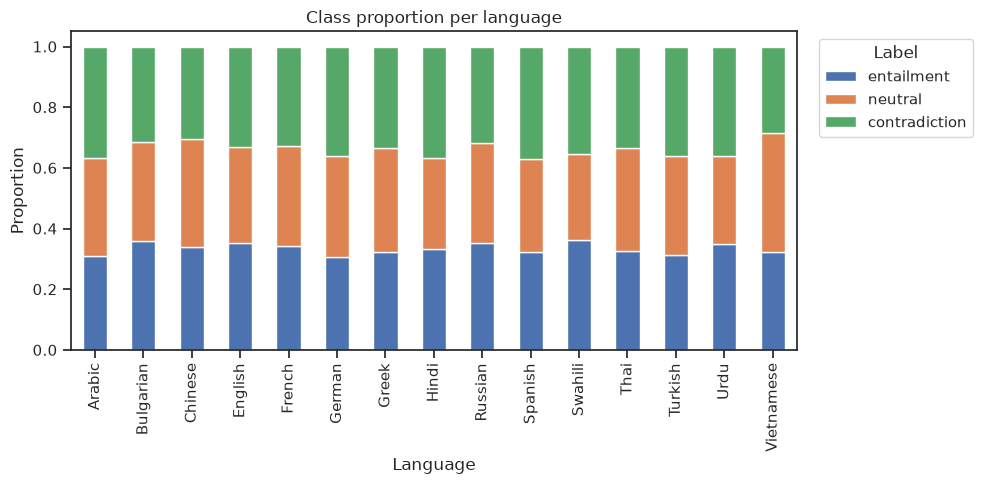

Chi-square test for language-label: chi2=33.1, degrees of freedom=28, p=0.231
This test does not show a clear statistical association between language and label.


In [65]:
from scipy.stats import chi2_contingency

# label counts and proportions per language
language_class_counts = pd.crosstab(df_train["language"], df_train["label"])
language_class_counts = language_class_counts.rename(columns=result_dict)
language_class_proportions = language_class_counts.div(
    language_class_counts.sum(axis=1), axis=0
)

print("Class proportions per language:")
display((language_class_proportions * 100).round(1))

# class proportions per language
language_class_proportions.plot(
    kind="bar", stacked=True, figsize=(10, 5))
plt.title("Class proportion per language")
plt.xlabel("Language")
plt.ylabel("Proportion")
plt.legend(title="Label", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Chi-square test between language code and label
chi2, p_value, degrees_of_freedom, _ = chi2_contingency(
    pd.crosstab(df_train["lang_abv"], df_train["label"])
)

print(
    f"Chi-square test for language-label: chi2={chi2:.1f}, "
    f"degrees of freedom={degrees_of_freedom}, p={p_value:.3f}"
)

if p_value < 0.05:
    print("This test shows a statistical association between language and label.")
else:
    print("This test does not show a clear statistical association between language and label.")


Here we can see a table of proportions by language, which shows that for most languages, each class represents approximately one-third of the total, demonstrating that the distribution is fairly balanced.

On the other hand, in the Chi-square statistical test, since the p-value of 0.231 is greater than the threshold of 0.05, we can conclude that there is no clear association between the language and the chosen class.

## 7. Relation between negation and labels

We look for some common forms (`no`, `not`, `never`, `cannot`, and contractions like `don't`)  to see the relation between these negations and the class labels. In essence, negation can change the meaning of a sentence, so we will not remove them automatically. 

,class,percentage
0,entailment,13.6
1,neutral,14.3
2,contradiction,34.8


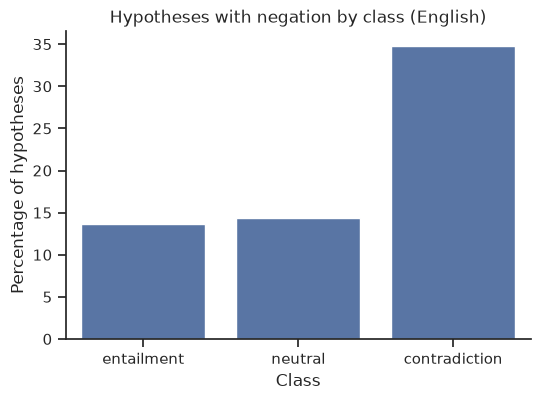

In [66]:
negation_pattern = r"\b(?:no|not|never|cannot)\b|\w+n['’]t\b"
eng_df_train = df_train[df_train["lang_abv"] == "en"].copy()

# detect if hypothesis has negation
eng_df_train["has_negation"] = eng_df_train["hypothesis"].str.contains(
    negation_pattern, case=False, regex=True, na=False
)

negation_by_class = (eng_df_train.groupby("label")["has_negation"].mean().reset_index())
negation_by_class["class"] = negation_by_class["label"].map(result_dict)
negation_by_class["percentage"] = negation_by_class["has_negation"] * 100

display(negation_by_class[["class", "percentage"]].round(1))

sns.set_theme(style="ticks")
fig, ax = plt.subplots(figsize=(6, 4))

ax = sns.barplot(data=negation_by_class,x="class",y="percentage",ax=ax)

ax.set_title("Hypotheses with negation by class (English)")
ax.set_xlabel("Class")
ax.set_ylabel("Percentage of hypotheses")

sns.despine()
plt.show()

We can see that, compared to 'entailment' and 'neutral', 'contradiction' has twice the frequency of negated hypotheses, so we could take this as a predictive signal for identifying contradictions. This information could be relevant when deciding whether or not to remove stop words that indicate negation.

## 8. Conclusions
This is a summary of the conclusions gathered after the EDA phase:

| Section | Data | Explanation|
|---|---|---|
| Missing values | 0 | There's no need to input data nor drop rows
| Class frequency | 34.5, 32, 33.5 | Balanced. No need to do oversampling or undersampling
| Languages | english (56,7%) rest (~3%) | Theres no single linguistic treatment.
| duplicate data | 0 |There is no data to delete
| Repeated premises | 2,800 premises appear 2–3 times - 6,711 rows (55%) | Do not delete. Be careful of data leakage in the train-test partition.
| Repeated hypothesis | 1 in 2 rows | Not relevant.
| Premise = Hypothesis | 1 | Not relevant for now.
|Text length | P_len = 50-200 H_len = 30-80 | Premises longer than hypotheses. Differences in the treatment of space (words) and character separation in different languages. Relevant for split in tokenization.
|Language vs Label | p = 0.231 | For each language, each label represents one-third of the total. There is no relationship between language and label.
| Negations (eng) | 14,8% entailment, 15,0% neutral, 38,7% contradiction | Possible indicator of contradiction, relevance of negation in this context.

